# 09 - Slope fields and what a solution is

**MATH 331 - Differential Equations.** Lecture plan: Session 3 (Unit 1: definitions, verifying solutions, initial value problems, direction fields).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 0.2** (what a solution is; Exercises 0.2.1-0.2.3, 0.2.6,
  0.2.13, 0.2.15), **Section 0.3** (classification), **Section 1.2** (slope fields; Figures
  1.2.1-1.2.6, Examples 1.2.2 and 1.2.3, Exercises 1.2.1 and 1.2.6).
* Exercise numbers are those of the exercise lists at the end of each chapter of the
  LibreTexts edition, unless "in the text" is said.
* Prerequisites: videos R01 (derivatives), R08 (linear systems), R11 (graphs); notebook 08.

**What you will learn**
1. To classify an equation: its order, and whether it is linear.
2. To **check** a solution: only derivatives are needed, no method.
3. How conditions select one solution from a family: initial and boundary conditions.
4. To read a **slope field**: the equation gives a slope at every point, a solution is a curve
   that follows the slopes.

No equation is *solved by a method* in this notebook: that starts in Session 4.

## 1. Theory in brief

* A **differential equation** relates an unknown function to its derivatives. It is *ordinary*
  (an ODE) when the unknown depends on one variable.
* Its **order** is the order of the highest derivative in it.
* It is **linear** when the unknown $y$ and its derivatives appear to the first power, are not
  multiplied together and are not inside another function; the coefficients may depend on $x$:

  $$ a_n(x)\,y^{(n)} + \dots + a_1(x)\,y' + a_0(x)\,y = g(x) . $$

  Otherwise it is **nonlinear**.
* A **solution** on an interval is a function that, put into the equation, makes it true for
  every $x$ of the interval. The **general solution** is a family of solutions with as many
  arbitrary constants as the order (a few equations also have solutions outside the family:
  notebook 10).
* An **initial value problem** gives the equation and the values of $y, y', \dots$ at **one**
  point: $y(x_0) = y_0$. A **boundary value problem** gives values at **two** points.
* For a first-order equation $y' = f(x, y)$, the **slope field** (or direction field) is the
  picture with a short segment of slope $f(x, y)$ at each point $(x, y)$ of a grid.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: slope_field, solution_curve, check).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. Classify

Six equations you will meet in this course:

| Equation | Where it comes from | Order | Linear? |
|---|---|---|---|
| $T' = -k\,(T - T_{room})$ | cooling of the coffee (Session 1) | 1 | yes |
| $x' = kx\,(M - x)$ | logistic growth of a population (notebook 03) | 1 | **no**: it contains $x^2$ |
| $\theta'' + \dfrac{g}{L}\sin\theta = 0$ | pendulum | 2 | **no**: $\theta$ is inside a sine |
| $LQ'' + RQ' + \dfrac{1}{C}Q = E(t)$ | electrical circuit | 2 | yes |
| $y' = xy$ | Lebl, Section 1.2 | 1 | yes: the coefficient $x$ does not contain $y$ |
| $m x'' + c x' + k x = 0$ | mass on a spring with a damper | 2 | yes |

For small angles $\sin\theta \approx \theta$ (first term of the Taylor series, video R09), and the
pendulum becomes $\theta'' + \tfrac{g}{L}\theta = 0$: linear, and the same equation as the spring
without damper. Linear equations are the ones we can solve systematically; that is why so much of
the course is about them.

## 3. Verify a solution

To **find** a solution you need a method. To **check** one you only need to differentiate: put
the candidate into the equation and see whether the two sides agree.

*Lebl, Exercises 0.2.1 and 0.2.2.* Is $x = e^{4t}$ a solution of
$x''' - 12x'' + 48x' - 64x = 0$? And $x = e^{t}$?

By hand: for $x = e^{4t}$ the derivatives are $4e^{4t}$, $16e^{4t}$, $64e^{4t}$, so the left side
is $(64 - 12\cdot 16 + 48\cdot 4 - 64)\,e^{4t} = 0$: yes. For $x = e^{t}$ all derivatives are
$e^t$, and the left side is $(1 - 12 + 48 - 64)\,e^{t} = -27e^{t}$, which is not zero: no.

With SymPy we compute the **residual**: left side minus right side. A solution has residual 0.

In [2]:
t, x = sp.symbols("t x")


def residual(left, right=0):
    # left side minus right side of an equation, simplified: 0 for a solution
    return sp.simplify(left - right)


def third_order(X):
    # the left side of  x''' - 12 x'' + 48 x' - 64 x = 0  for a candidate X(t)
    return sp.diff(X, t, 3) - 12 * sp.diff(X, t, 2) + 48 * sp.diff(X, t) - 64 * X


print("x = exp(4t):", residual(third_order(sp.exp(4 * t))))
print("x = exp(t) :", residual(third_order(sp.exp(t))))

assert residual(third_order(sp.exp(4 * t))) == 0
assert residual(third_order(sp.exp(t))) == -27 * sp.exp(t)

x = exp(4t): 0


x = exp(t) : -27*exp(t)


Two more, to do by hand first.

* *Lebl, Exercise 0.2.3.* Is $y = \sin t$ a solution of $(y')^2 = 1 - y^2$?
* *Lebl, Exercise 0.2.13.* Is $y = x^2$ a solution of $x^2 y'' - 2y = 0$?

In [3]:
candidate = sp.sin(t)
print("Exercise 0.2.3 :", residual(sp.diff(candidate, t) ** 2, 1 - candidate ** 2))

candidate = x ** 2
print("Exercise 0.2.13:", residual(x ** 2 * sp.diff(candidate, x, 2) - 2 * candidate))

assert residual(sp.diff(sp.sin(t), t) ** 2, 1 - sp.sin(t) ** 2) == 0
assert residual(x ** 2 * sp.diff(x ** 2, x, 2) - 2 * x ** 2) == 0

Exercise 0.2.3 : 0
Exercise 0.2.13: 0


Both residuals are 0: both are solutions (the first because $\cos^2 t = 1 - \sin^2 t$).

**Remember this habit.** Whatever method you use later in the course, the answer can always be
checked in this way, by hand, in a minute.

## 4. From a family to one solution

*Lebl, Exercise 0.2.15.* Every function $x = C_1 e^{t} + C_2$ is a solution of $x'' - x' = 0$:
a second-order equation, two arbitrary constants. The **initial conditions** $x(0) = 10$,
$x'(0) = 100$ select one of them. By hand:

$$
x(0) = C_1 + C_2 = 10, \qquad x'(0) = C_1 = 100 \quad\Longrightarrow\quad C_1 = 100,\ C_2 = -90 .
$$

It is a linear system for the constants, as in notebook 08.

In [4]:
C1, C2 = sp.symbols("C1 C2")
family = C1 * sp.exp(t) + C2

print("residual of the family:", residual(sp.diff(family, t, 2) - sp.diff(family, t)))

conditions = [family.subs(t, 0) - 10,                     # x(0) = 10
              sp.diff(family, t).subs(t, 0) - 100]        # x'(0) = 100
constants = sp.solve(conditions, [C1, C2])
print("constants:", constants)
print("solution : x =", family.subs(constants))

assert constants == {C1: 100, C2: -90}                    # the answer printed in Lebl

residual of the family: 0
constants: {C1: 100, C2: -90}
solution : x = 100*exp(t) - 90


**Initial conditions against boundary conditions.** The solutions of $y'' + y = 0$ are
$y = a\cos x + b\sin x$ (Session 11). Two conditions at the *same* point always select exactly
one solution. Two conditions at *different* points may not:

In [5]:
a, b = sp.symbols("a b")
oscillation = a * sp.cos(x) + b * sp.sin(x)
assert residual(sp.diff(oscillation, x, 2) + oscillation) == 0

BOUNDARY_PROBLEMS = ((sp.pi / 2, 1), (sp.pi, 0), (sp.pi, 1))       # (x_end, required y(x_end))

for x_end, y_end in BOUNDARY_PROBLEMS:
    found = sp.solve([oscillation.subs(x, 0),                     # y(0) = 0
                      oscillation.subs(x, x_end) - y_end], [a, b], dict=True)
    print(f"y(0) = 0, y({x_end}) = {y_end}:  {found}")

y(0) = 0, y(pi/2) = 1:  [{a: 0, b: 1}]
y(0) = 0, y(pi) = 0:  [{a: 0}]
y(0) = 0, y(pi) = 1:  []


Read the three lines:

* $y(0) = 0$, $y(\pi/2) = 1$: one solution, $y = \sin x$;
* $y(0) = 0$, $y(\pi) = 0$: $a = 0$ and $b$ is free: **infinitely many** solutions, $y = b\sin x$;
* $y(0) = 0$, $y(\pi) = 1$: the empty list, **no solution**.

Boundary value problems come back in Session 16.

## 5. The slope field

For a first-order equation $y' = f(x, y)$ the right-hand side is a **recipe for slopes**: at the
point $(x, y)$, a solution passing there must have slope $f(x, y)$.

*Lebl, Figure 1.2.1.* For $y' = xy$, at the point $(2, 1.5)$ the slope is $2 \times 1.5 = 3$.

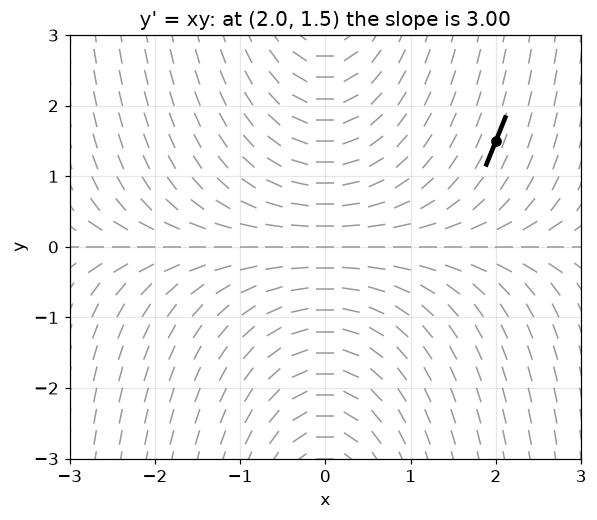

In [6]:
def f_xy(x, y):
    return x * y


X_RANGE = (-3.0, 3.0)
Y_RANGE = (-3.0, 3.0)
FIGURE_SIZE = (6.0, 5.0)
HALF_LENGTH = 0.35              # half the length of the highlighted segment
POINT = (2.0, 1.5)              # the point of Lebl's Figure 1.2.1


def plot_slope_at(px=POINT[0], py=POINT[1]):
    slope = f_xy(px, py)
    dx = HALF_LENGTH / np.hypot(1.0, slope)               # a segment of fixed length
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, f_xy, X_RANGE, Y_RANGE)
    ax.plot([px - dx, px + dx], [py - slope * dx, py + slope * dx], "-", color="black", linewidth=3)
    ax.plot(px, py, "o", color="black")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"y' = xy: at ({px:.1f}, {py:.1f}) the slope is {slope:.2f}")
    plt.show()


plot_slope_at()
assert f_xy(*POINT) == 3

*The plot shows* the slope field of $y' = xy$ (Lebl, Figure 1.2.2): short grey segments on a
grid. The thick black segment at $(2, 1.5)$ has slope 3. The segments are horizontal on both
axes (where $xy = 0$) and get steeper away from them.

**Slider.** Before moving the point, answer: where is the slope **negative**? Where is it
exactly 1?

In [7]:
STEP = 0.1

interact(plot_slope_at,
         px=FloatSlider(value=POINT[0], min=X_RANGE[0], max=X_RANGE[1], step=STEP,
                        description="x", continuous_update=False),
         py=FloatSlider(value=POINT[1], min=Y_RANGE[0], max=Y_RANGE[1], step=STEP,
                        description="y", continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='x', max=3.0, min=-3.0), Flo...

(The slope is negative where $x$ and $y$ have opposite signs; it is 1 on the curve $xy = 1$.)

**By hand: isoclines.** Nobody draws hundreds of segments by hand. Instead, find the curves on which the
slope has the **same** value $c$: the *isoclines* $f(x, y) = c$. For

$$ y' = x - y $$

the slope is $c$ on the line $y = x - c$: slope 0 on $y = x$, slope 1 on $y = x - 1$, slope $-1$
on $y = x + 1$. Draw these lines, put segments of slope $c$ along each, and the field appears.

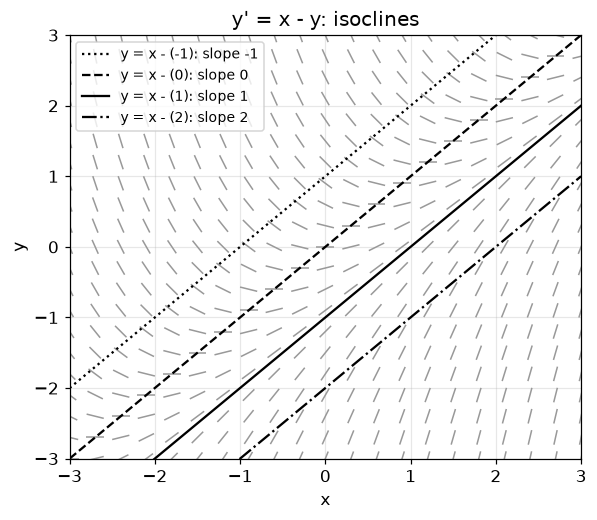

In [8]:
def f_x_minus_y(x, y):
    return x - y


ISOCLINE_SLOPES = (-1, 0, 1, 2)
LINE_STYLES = (":", "--", "-", "-.")

x_line = np.linspace(*X_RANGE, 2)                         # two points are enough for a line

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, f_x_minus_y, X_RANGE, Y_RANGE)
for c, style in zip(ISOCLINE_SLOPES, LINE_STYLES):
    ax.plot(x_line, x_line - c, style, color="black", linewidth=1.5, label=f"y = x - ({c}): slope {c}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = x - y: isoclines")
ax.legend(loc="upper left")
plt.show()

line = x - 1                                              # the isocline of slope 1
assert residual(sp.diff(line, x), x - line) == 0          # it is itself a solution

*The plot shows* the slope field of $y' = x - y$ with four parallel black lines, the isoclines
of slope $-1$ (dotted), 0 (dashed), 1 (solid) and 2 (dash-dot). Along each line all the grey
segments have the same slope.

Look at the solid line $y = x - 1$: along it the slope is 1, and the line itself has slope 1. So
it follows its own slopes: **it is a solution**, found without any method. The last line of the
cell checks it. The other solutions approach it as $x$ grows (you will prove it in Session 5:
$y = x - 1 + Ce^{-x}$).

## 6. Solutions follow the slopes

A solution is a curve that is tangent to the segments at every point. An **initial condition**
$y(x_0) = y_0$ says through which point the curve passes.

*Lebl, Figure 1.2.3.* $y' = xy$ with $y(0) = 0.2$, $y(0) = 0$ and $y(0) = -0.2$. The curves are
computed numerically by `ol.solution_curve`, which takes many small steps along the slopes, to
the left and to the right of the starting point (Session 8 explains how).

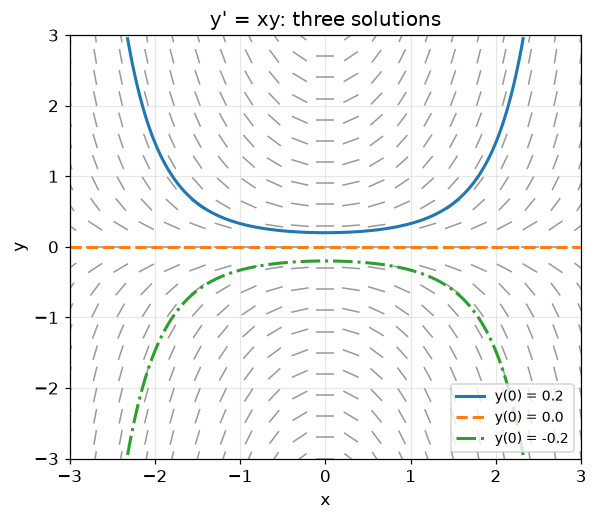

y(2) for y(0) = 0.2: numerical 1.4778, formula 1.4778


In [9]:
INITIAL_VALUES = (0.2, 0.0, -0.2)
CURVE_STYLES = ("-", "--", "-.")
X_CHECK = 2.0

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, f_xy, X_RANGE, Y_RANGE)
for y0, style in zip(INITIAL_VALUES, CURVE_STYLES):
    x_curve, y_curve = ol.solution_curve(f_xy, (0.0, y0), X_RANGE, Y_RANGE)
    ax.plot(x_curve, y_curve, style, linewidth=2, label=f"y(0) = {y0}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = xy: three solutions")
ax.legend(loc="lower right")
plt.show()

# Check against the formula y = y0 exp(x^2 / 2) (Session 4 shows how to find it).
y0 = INITIAL_VALUES[0]
x_curve, y_curve = ol.solution_curve(f_xy, (0.0, y0), X_RANGE, Y_RANGE)
numerical, exact = np.interp(X_CHECK, x_curve, y_curve), y0 * np.exp(X_CHECK ** 2 / 2)
print(f"y({X_CHECK:.0f}) for y(0) = {y0}: numerical {numerical:.4f}, formula {exact:.4f}")
assert np.isclose(numerical, exact)
assert residual(sp.diff(y0 * sp.exp(x ** 2 / 2), x), x * y0 * sp.exp(x ** 2 / 2)) == 0

*The plot shows* three curves on the slope field of $y' = xy$. The one through $(0, 0.2)$
(solid) is a valley that rises steeply on both sides; the one through $(0, -0.2)$ (dash-dot) is
its mirror image, falling on both sides; the one through $(0, 0)$ (dashed) is the $x$ axis.

A small change of the initial value, from $0.2$ to $-0.2$, gives a completely different
behaviour. You can see it from the slope field alone, **without solving the equation**.

**Slider.** Before moving it: for which initial values $y(0)$ does the solution stay bounded?

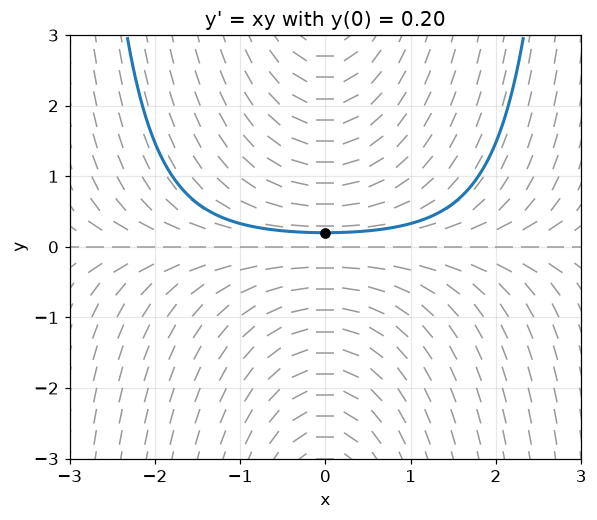

In [10]:
def plot_initial_value(y0=INITIAL_VALUES[0]):
    x_curve, y_curve = ol.solution_curve(f_xy, (0.0, y0), X_RANGE, Y_RANGE)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, f_xy, X_RANGE, Y_RANGE)
    ax.plot(x_curve, y_curve, "-", linewidth=2)
    ax.plot(0.0, y0, "o", color="black")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"y' = xy with y(0) = {y0:.2f}")
    plt.show()


plot_initial_value()

In [11]:
Y0_RANGE = (-2.0, 2.0, 0.05)            # minimum, maximum, step

interact(plot_initial_value,
         y0=FloatSlider(value=INITIAL_VALUES[0], min=Y0_RANGE[0], max=Y0_RANGE[1], step=Y0_RANGE[2],
                        description="y(0)", continuous_update=False));

interactive(children=(FloatSlider(value=0.2, continuous_update=False, description='y(0)', max=2.0, min=-2.0, s...

(Only $y(0) = 0$: every other solution leaves any strip around the axis.)

*Lebl, Figure 1.2.4.* A different behaviour: for $y' = -y$ all solutions come together.

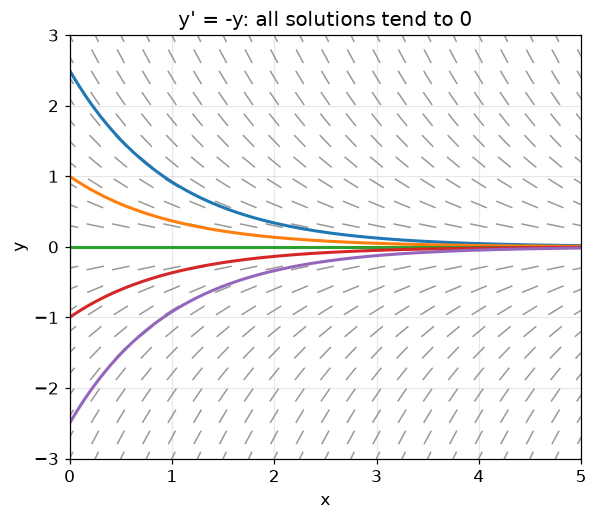

In [12]:
def f_decay(x, y):
    return -y


DECAY_X_RANGE = (0.0, 5.0)
DECAY_VALUES = (2.5, 1.0, 0.0, -1.0, -2.5)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, f_decay, DECAY_X_RANGE, Y_RANGE)
for y0 in DECAY_VALUES:
    x_curve, y_curve = ol.solution_curve(f_decay, (0.0, y0), DECAY_X_RANGE, Y_RANGE)
    ax.plot(x_curve, y_curve, "-", linewidth=2)
    assert np.isclose(y_curve[-1], y0 * np.exp(-DECAY_X_RANGE[1]))        # y = y0 exp(-x)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = -y: all solutions tend to 0")
plt.show()

*The plot shows* five solutions of $y' = -y$ starting at $x = 0$ from $2.5$, $1$, $0$, $-1$ and
$-2.5$. All of them approach the $x$ axis as $x$ grows; the one starting at 0 stays on it.

Here a small change of the initial value hardly matters after a while. The slopes do not depend
on $x$ (the picture is the same in every column): the equation is **autonomous** (Session 7).

## 7. What a picture cannot tell you

In the pictures above, exactly one curve passes through each point. Is it always so?

*Lebl, Example 1.2.2 and Figure 1.2.6.* The problem

$$ y' = 2\sqrt{|y|}, \qquad y(0) = 0 $$

has the solution $y = 0$. But $y = x^2$ (for $x \ge 0$) is **another** solution through the same
point: $y' = 2x = 2\sqrt{x^2}$.

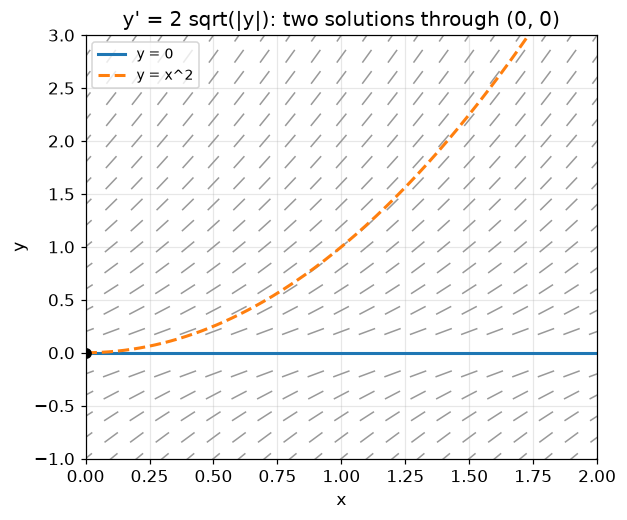

In [13]:
def f_root(x, y):
    return 2 * np.sqrt(np.abs(y))


ROOT_X_RANGE = (0.0, 2.0)
ROOT_Y_RANGE = (-1.0, 3.0)
x_right = np.linspace(*ROOT_X_RANGE, 200)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ol.slope_field(ax, f_root, ROOT_X_RANGE, ROOT_Y_RANGE)
ax.plot(x_right, np.zeros_like(x_right), "-", linewidth=2, label="y = 0")
ax.plot(x_right, x_right ** 2, "--", linewidth=2, label="y = x^2")
ax.plot(0.0, 0.0, "o", color="black")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y' = 2 sqrt(|y|): two solutions through (0, 0)")
ax.legend(loc="upper left")
plt.show()

x_pos = sp.symbols("x_pos", positive=True)
for solution in (sp.Integer(0), x_pos ** 2):
    assert residual(sp.diff(solution, x_pos), 2 * sp.sqrt(sp.Abs(solution))) == 0

*The plot shows* two curves starting from the same point $(0, 0)$ of the slope field of
$y' = 2\sqrt{|y|}$: the $x$ axis (solid) and the parabola $y = x^2$ (dashed). Both follow the
grey segments.

Looking at the slope field you could not have guessed it. So two questions must be answered by a
**theorem**, not by a picture: *does a solution exist? Is it the only one?* That is Picard's
theorem, in Session 5 (notebook 11). Exercise 4 below shows the other thing that can go wrong.

## 8. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

*Lebl, Exercise 1.2.6.* The next cell draws three slope fields, A, B and C. Match them with

1. $y' = 1 - x$
2. $y' = x - 2y$
3. $y' = x\,(1 - y)$

Work by hand: where is the slope zero? Does the slope depend on $y$? Then type the number of the
equation of each picture in place of `None`.

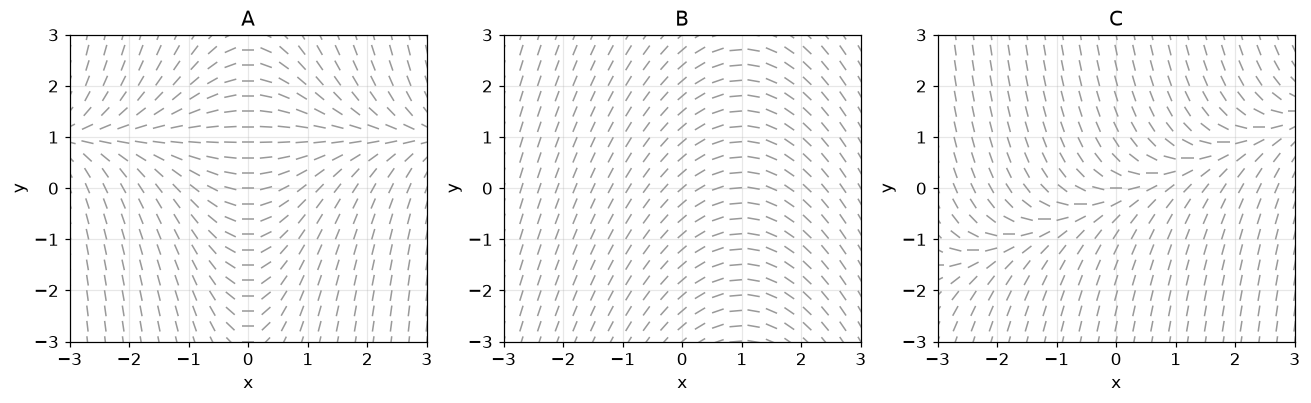

In [14]:
EQUATIONS = (lambda x, y: 1 - x + 0 * y,                  # equation 1
             lambda x, y: x - 2 * y,                      # equation 2
             lambda x, y: x * (1 - y))                    # equation 3
LETTERS = ("A", "B", "C")
ORDER = np.argsort(np.sin(np.arange(1, len(EQUATIONS) + 1)))      # the order is hidden on purpose
WIDE_FIGURE = (12.0, 3.8)

fig, axes = plt.subplots(1, len(EQUATIONS), figsize=WIDE_FIGURE)
for ax, letter, k in zip(axes, LETTERS, ORDER):
    ol.slope_field(ax, EQUATIONS[k], X_RANGE, Y_RANGE)
    ax.set_title(letter)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

In [15]:
my_A = None
my_B = None
my_C = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

my_matching = None if None in (my_A, my_B, my_C) else [my_A, my_B, my_C]
ol.check("Exercise 1", my_matching, ORDER + 1);

Exercise 1: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** Give the order of each equation, and say whether it is linear (`True`) or not (`False`):

1. $y'' + 3y' + 2y = \sin x$
2. $y' = y^2$
3. $x^2 y''' + y = 0$
4. $y\,y' = x$

Type two lists in place of `None`, for example `[1, 1, 1, 1]` and `[True, True, True, True]`.

In [16]:
my_orders = None
my_linear = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

ol.check("Exercise 2a, orders", my_orders, [2, 1, 3, 1])
ol.check("Exercise 2a, linear", my_linear, [True, False, True, False]);

Exercise 2a, orders: no answer yet (replace None with your value)
Exercise 2a, linear: no answer yet (replace None with your value)


**(b)** *Lebl, Exercise 0.2.6.* Verify by hand that $x = C_1 e^{-t} + C_2 e^{2t}$ is a solution of
$x'' - x' - 2x = 0$. Then find $C_1$ and $C_2$ so that $x(0) = 10$ and $x'(0) = 0$. Fractions can
be typed as they are, for example `7/2`.

In [17]:
my_C1 = None
my_C2 = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

family_b = C1 * sp.exp(-t) + C2 * sp.exp(2 * t)
expected_b = sp.solve([family_b.subs(t, 0) - 10, sp.diff(family_b, t).subs(t, 0)], [C1, C2])
ROUNDING = 1e-3                 # an answer rounded to three decimals is accepted

my_constants = None if None in (my_C1, my_C2) else [my_C1, my_C2]
ol.check("Exercise 2b", my_constants, [float(expected_b[C1]), float(expected_b[C2])], tol=ROUNDING);

Exercise 2b: no answer yet (replace None with your value)


### Exercise 3 - Fill in

*Lebl, Exercise 1.2.1.* Complete the function `f` for the equation $y' = e^{x - y}$ (use
`np.exp`). The next cell checks three slopes computed by hand and draws the slope field.

In [18]:
def f(x, y):
    return None                 # replace None with the formula

In [19]:
if f(0.0, 0.0) is None:
    print("Exercise 3: complete f(x, y) first")
else:
    assert np.isclose(f(0.0, 0.0), 1.0), "at (0, 0) the slope is e^0 = 1"
    assert np.isclose(f(1.0, 1.0), 1.0), "at (1, 1) the slope is e^0 = 1"
    assert np.isclose(f(1.0, 0.0), np.e), "at (1, 0) the slope is e"
    print("Exercise 3: correct")
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ol.slope_field(ax, f, X_RANGE, Y_RANGE)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("y' = exp(x - y)")
    plt.show()

Exercise 3: complete f(x, y) first


Look at your picture: along one straight line the segments point along the line itself. Guess a
solution $y(x)$, type it as a SymPy expression in `x` in place of `None`, and the cell computes
its residual.

In [20]:
my_solution = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

if my_solution is None:
    print("Exercise 3, your solution: no answer yet (replace None with an expression in x)")
else:
    my_residual = residual(sp.diff(my_solution, x), sp.exp(x - my_solution))
    print("residual:", my_residual)
    print("Exercise 3, your solution:", "correct" if my_residual == 0 else "not yet (the residual is not 0)")

Exercise 3, your solution: no answer yet (replace None with an expression in x)


### Exercise 4 - Explore

*Lebl, Example 1.2.3.* Draw the slope field of $y' = y^2$ and the solutions with $y(0) = 1$ and
$y(0) = \tfrac12$ (copy the first cell of Section 6 and change it; use a taller window, for
example `(-1.0, 8.0)` for $y$).

* How far to the right does each curve go before leaving the picture?
* Check by hand that $y = \dfrac{1}{1/A - x}$ is the solution with $y(0) = A$. What happens to it
  at $x = 1/A$?
* The equation $y' = y^2$ "looks nice" everywhere. What does this example say about the sentence
  "the solution exists"?

In [21]:
# your code here

## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. A is equation 3 (segments horizontal on the line $y = 1$ and on the $y$ axis); B is equation 1
   (the slope does not depend on $y$: every column is made of parallel segments, horizontal at
   $x = 1$); C is equation 2 (segments horizontal on the line $y = x/2$).
2. (a) Orders 2, 1, 3, 1; linear: yes, no ($y^2$), yes, no ($y$ times $y'$).
   (b) $C_1 = \tfrac{20}{3}$, $C_2 = \tfrac{10}{3}$.
3. `return np.exp(x - y)`. On the line $y = x$ the slope is $e^0 = 1$, the slope of the line:
   $y = x$ is a solution. (All solutions: $y = \ln(e^x + C)$; they approach $y = x$ as $x$ grows.)
4. The solutions are $y = \dfrac{1}{1 - x}$ and $y = \dfrac{1}{2 - x}$: they go to infinity at
   $x = 1$ and $x = 2$. A solution may exist only on a short interval, even for a harmless-looking
   equation.

</details>

**Where to go next:** notebook 01 (exponential growth) uses these ideas on the first model of the
course; notebook 10 (separable equations, Session 4) is the first method.